# **Sparkle-movie**

Use Apache Spark in python, to develop, to train, and to deploy a model of recomandations of movies (Netflix's type).

### **1. Prepare the environment**

In [1]:
import os
import sys
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, FloatType

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import glob
import shutil
import stat

import numpy as np
import matplotlib.ticker as mticker

# - - - - - - - - - WINDOWS / HADOOP - - - - - - - - - #
# Spark uses Hadoop libraries to write on disk : on Windows, it needs winutils.exe + hadoop.dll
HADOOP_HOME = r"C:\hadoop"
for file in ("winutils.exe", "hadoop.dll"):
    if not os.path.exists(os.path.join(HADOOP_HOME, "bin", file)):
        raise FileNotFoundError(f"Missing {file} in {HADOOP_HOME}\\bin")

os.environ["HADOOP_HOME"] = HADOOP_HOME
os.environ["PATH"] = os.path.join(HADOOP_HOME, "bin") + os.pathsep + os.environ["PATH"]

# Python workers (UDF, RDD...) must use the same Python as the notebook (.venv)
os.environ["PYSPARK_PYTHON"] = sys.executable

# - - - - - - - - - SPARK SESSION - - - - - - - - - #
# Env variables and configs are read only when the JVM starts : restart the kernel after any change
spark = (
    SparkSession.builder
    .appName("SparkleMovie")
    .master("local[*]")                            # Local mode, uses all CPU cores
    .config("spark.driver.memory", "8g")           # Local mode : driver = executor (PC has 16 GB RAM)
    .config("spark.sql.shuffle.partitions", "24")  # ~2 x CPU cores, instead of 200 by default
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")  # Hide INFO logs

print("Spark", spark.version, "| UI :")
""", spark.sparkContext.uiWebUrl)"""

Spark 4.0.5 | UI :


', spark.sparkContext.uiWebUrl)'

In [2]:
# - - - - - - - - - UTILS : SAVE CSV - - - - - - - - - #
def _remove_readonly(func, path, _):
    # Windows / OneDrive can flag files or folders as read-only : remove the flag, then retry
    os.chmod(path, stat.S_IWRITE)
    func(path)


def save_csv(df, file_path):
    tmp_dir = os.path.join(os.path.dirname(file_path), "_tmp_spark")

    # 1. Spark always writes a folder : 1 partition -> 1 part-xxxx.csv file (+ _SUCCESS, .crc)
    (
        df.coalesce(1)
        .write.mode("overwrite")
        .option("header", True)
        .option("escape", '"')  # CSV standard : a quote inside a field is doubled (""), as Tableau / Excel expect
        .csv(tmp_dir)
    )

    # 2. Move + rename the part file (os.replace overwrites the previous version)
    part_file = glob.glob(os.path.join(tmp_dir, "part-*.csv"))[0]
    os.replace(part_file, file_path)

    # 3. Delete the temporary folder and its technical files (_SUCCESS, .crc)
    shutil.rmtree(tmp_dir, onexc=_remove_readonly)

### **2.Load and explore datas**

####  a) Import files into dataframes spark, and show 10 first lines

In [3]:
# - - - - - - - - - MOVIES - - - - - - - - - #
print("< - - - - - - MOVIES FILE - - - - - - >")
df_movies = spark.read.csv(
    "data/raw/movies.csv",
    header=True,       # Use first line as a column
    inferSchema=True,  # Auto-detect type in columns
    sep=",",           # Delimiter (ex. ";" EUROPE CSV)
    encoding="utf-8",
    escape='"',        # Quotes inside a title are doubled ("") : without it, 26 titles are badly parsed
)
df_movies.show(10, truncate=False)

# - - - - - - - - - RATINGS - - - - - - - - - #
print("< - - - - - - RATINGS FILE - - - - - - >")
df_ratings = spark.read.csv(
    "data/raw/ratings.csv",
    header=True,       # Use first line as a column
    inferSchema=True,  # Auto-detect type in columns
    sep=",",           # Delimiter (ex. ";" EUROPE CSV)
    encoding="utf-8",
)
df_ratings.show(10, truncate=False)


"""
# - - - - - TAGS - - - - - #
print("< - - - - - - TAGS FILE - - - - - - >")
df_tags = spark.read.csv(
    "data/raw/tags.csv",
    header=True,       # Use first line as a column
    inferSchema=True,  # Auto-detect type in columns
    sep=",",           # Delimiter (ex. ";" EUROPE CSV)
    encoding="utf-8",
)
df_tags.show(10)
df_tags.printSchema()
"""

< - - - - - - MOVIES FILE - - - - - - >
+-------+----------------------------------+-------------------------------------------+
|movieId|title                             |genres                                     |
+-------+----------------------------------+-------------------------------------------+
|1      |Toy Story (1995)                  |Adventure|Animation|Children|Comedy|Fantasy|
|2      |Jumanji (1995)                    |Adventure|Children|Fantasy                 |
|3      |Grumpier Old Men (1995)           |Comedy|Romance                             |
|4      |Waiting to Exhale (1995)          |Comedy|Drama|Romance                       |
|5      |Father of the Bride Part II (1995)|Comedy                                     |
|6      |Heat (1995)                       |Action|Crime|Thriller                      |
|7      |Sabrina (1995)                    |Comedy|Romance                             |
|8      |Tom and Huck (1995)               |Adventure|Children        

'\n# - - - - - TAGS - - - - - #\nprint("< - - - - - - TAGS FILE - - - - - - >")\ndf_tags = spark.read.csv(\n    "data/raw/tags.csv",\n    header=True,       # Use first line as a column\n    inferSchema=True,  # Auto-detect type in columns\n    sep=",",           # Delimiter (ex. ";" EUROPE CSV)\n    encoding="utf-8",\n)\ndf_tags.show(10)\ndf_tags.printSchema()\n'

#### b) Cleaning dataframes (missing values, doubles...)

In [4]:
# - - - - - - - - - MOVIES - - - - - - - - - #
print("< - - - - - - MOVIES FILE - - - - - - >")
# Type of each column and number of non-empty values
df_movies.printSchema()

# Missing values, only for the columns that have some
exprs = []
for field in df_movies.schema.fields:
  col_name = field.name
  if isinstance(field.dataType, (DoubleType, FloatType)):
    cond = F.col(col_name).isNull() | F.isnan(col_name)
  else:
    cond = F.col(col_name).isNull()
  exprs.append(F.count(F.when(cond, col_name)).alias(col_name))

print(f"Missing issues : {df_movies.select(exprs).show()}")

# Duplicates : links.csv gives the IMDb and TMDb ids of each film -> the same id = the same real film
df_links = spark.read.csv("data/raw/links.csv", header=True, inferSchema=True)
df_movies_links = df_movies.join(df_links, on="movieId", how="left")

# a) The same movieId on several lines
nb_dup_movie_ids = df_movies.count() - df_movies.select("movieId").distinct().count()

# b) The same title for several movieIds
nb_dup_titles = df_movies.groupBy("title").count().filter(F.col("count") > 1).count()

# c) The same IMDb id / TMDb id for several movieIds
nb_dup_imdb = df_links.groupBy("imdbId").count().filter(F.col("count") > 1).count()
nb_dup_tmdb = (
    df_links
    .filter(F.col("tmdbId").isNotNull())  # Some films have no TMDb id
    .groupBy("tmdbId")
    .count()
    .filter(F.col("count") > 1)
    .count()
)

# d) The same film registered twice = same TMDb id AND same title
#    -> merged into its oldest entry (smallest movieId), its ratings are moved in the RATINGS part
df_dup_films = (
    df_movies_links
    .filter(F.col("tmdbId").isNotNull())
    .groupBy("tmdbId", "title")
    .agg(
        F.count("*").alias("nb_movies"),
        F.min("movieId").alias("kept_movieId"),
    )
    .filter(F.col("nb_movies") > 1)
)
df_movie_id_map = (  # One line per duplicated entry : movieId to remove -> movieId kept
    df_movies_links
    .join(df_dup_films, on=["tmdbId", "title"])
    .filter(F.col("movieId") != F.col("kept_movieId"))
    .select("movieId", "kept_movieId", "title")
    .cache()
)

print(f"Duplicated movieId : {nb_dup_movie_ids}")
print(f"Titles shared by several movieIds : {nb_dup_titles}")
print(f"IMDb ids shared by several movieIds : {nb_dup_imdb}")
print(f"TMDb ids shared by several movieIds : {nb_dup_tmdb}")
print(f"-> same TMDb id + same title = same film registered twice (merged) : {df_dup_films.count()}")
df_movie_id_map.orderBy("title").show(25, truncate=False)
# Result :
# - IMDb ids are all unique
# - same TMDb id + same title (ex : Good Boys (2019) twice) : the same film registered twice -> merged
# - same TMDb id + different titles : alternative title or error in the TMDb link, can't be sure -> kept
# - same title + different ids : homonyms (remakes, different films released the same year...) -> kept

# Treatment
# Genres of a merged film = union of the genres of all its entries
# (ex : "Action|Adventure|Sci-Fi|Thriller" + "Adventure|Children|Sci-Fi|Thriller")
df_merged_entries = (  # All the entries of the merged films (kept + removed), with the movieId kept
    df_movie_id_map.select("movieId", "kept_movieId")
    .unionByName(df_movie_id_map.select(F.col("kept_movieId").alias("movieId"), "kept_movieId"))
    .distinct()
)
df_merged_genres = (
    df_movies
    .join(df_merged_entries, on="movieId")
    .withColumn("genre", F.explode(F.split("genres", r"\|")))
    .filter(F.col("genre") != "(no genres listed)")
    .groupBy("kept_movieId")
    .agg(F.array_join(F.array_sort(F.collect_set("genre")), "|").alias("merged_genres"))
    .withColumnRenamed("kept_movieId", "movieId")
)

# One line per movieId, without the duplicated entries of a same film, with the merged genres
df_clean_movies = (
    df_movies
    .dropDuplicates(["movieId"])
    .join(F.broadcast(df_movie_id_map), on="movieId", how="left_anti")  # Remove the duplicated entries
    .join(F.broadcast(df_merged_genres), on="movieId", how="left")
    .withColumn("genres", F.coalesce("merged_genres", "genres"))
    .select("movieId", "title", "genres")
    .orderBy("movieId")
    .cache()
)

# Save the clean version -> data/clean/movies/data_clean_movies.csv
save_csv(df_clean_movies, "data/clean/movies/data_clean_movies.csv")

print("Shape after cleaning :", (df_clean_movies.count(), len(df_clean_movies.columns)))



# - - - - - - - - - RATINGS - - - - - - - - - #
print("< - - - - - - RATINGS FILE - - - - - - >")
# Type of each column and number of non-empty values
df_ratings.printSchema()

# Missing values, only for the columns that have some
exprs_2 = []
for field in df_ratings.schema.fields:
  col_name = field.name
  if isinstance(field.dataType, (DoubleType, FloatType)):
    cond = F.col(col_name).isNull() | F.isnan(col_name)
  else:
    cond = F.col(col_name).isNull()
  exprs_2.append(F.count(F.when(cond, col_name)).alias(col_name))

print(f"Missing issues : {df_ratings.select(exprs_2).show()}")

# Duplicates
# a) Ratings of a duplicated film entry (see MOVIES) -> moved to the movieId kept
df_ratings_moved = df_ratings.join(
    F.broadcast(df_movie_id_map.select("movieId", "kept_movieId")), on="movieId", how="left"
)
nb_ratings_moved = df_ratings_moved.filter(F.col("kept_movieId").isNotNull()).count()
df_ratings_moved = (
    df_ratings_moved
    .withColumn("movieId", F.coalesce("kept_movieId", "movieId"))
    .select("userId", "movieId", "rating", "timestamp")
)

# b) The same user rating the same film several times (an exactly duplicated line is a particular case)
#    -> keep only the most recent rating : ALS needs ONE rating per (user, film) pair
#    (it happens when a user had rated the 2 entries of a merged film)
df_clean_ratings = (
    df_ratings_moved
    .groupBy("userId", "movieId")
    .agg(
        F.max_by("rating", "timestamp").alias("rating"),  # Rating given at the latest timestamp
        F.max("timestamp").alias("timestamp"),
    )
    .cache()  # Heavy to compute (32M lines) : kept in memory for all the next cells
)
nb_ratings_removed = df_ratings.count() - df_clean_ratings.count()

print(f"Ratings moved to the movieId kept : {nb_ratings_moved}")
print(f"Duplicated (userId, movieId) ratings removed : {nb_ratings_removed}")

# Save the clean version -> data/clean/ratings/data_clean_ratings.csv
save_csv(df_clean_ratings, "data/clean/ratings/data_clean_ratings.csv")

print("Shape after cleaning :", (df_clean_ratings.count(), len(df_clean_ratings.columns)))

< - - - - - - MOVIES FILE - - - - - - >
root
 |-- movieId: integer (nullable = true)
 |-- title: string (nullable = true)
 |-- genres: string (nullable = true)

+-------+-----+------+
|movieId|title|genres|
+-------+-----+------+
|      0|    0|     0|
+-------+-----+------+

Missing issues : None
Duplicated movieId : 0
Titles shared by several movieIds : 198
IMDb ids shared by several movieIds : 0
TMDb ids shared by several movieIds : 36
-> same TMDb id + same title = same film registered twice (merged) : 17
+-------+------------+----------------------------------------------------------------------------+
|movieId|kept_movieId|title                                                                       |
+-------+------------+----------------------------------------------------------------------------+
|191775 |66511       |Berlin Calling (2008)                                                       |
|144426 |5264        |Clockstoppers (2002)                                           

#### c) General data trends

○ Which films have the highest average ratings? </br>
○ Which film genres are the most popular?

In [5]:
# List of 5 films with the highest average ratings
MIN_RATINGS = 1000  # Minimum number of ratings for an average to be reliable

# 1. One line per film : average rating + number of ratings
df_movie_stats = (
    df_clean_ratings
    .groupBy("movieId")
    .agg(
        F.round(F.avg("rating"), 2).alias("avg_rating"),
        F.count("rating").alias("nb_ratings"),
    )
    .cache()  # Reused twice below : avoids re-reading the 32M ratings
)

# 2. Distribution of the number of ratings per film (justifies MIN_RATINGS)
quantiles = df_movie_stats.approxQuantile("nb_ratings", [0.25, 0.5, 0.75, 0.95], 0.01)
"""print("Nb ratings per film (Q1, median, Q3, 95%) :", quantiles)"""

# 3. Keep reliable films, add titles, sort, keep top 5
df_top5_movies = (
    df_movie_stats
    .filter(F.col("nb_ratings") >= MIN_RATINGS)
    .join(df_clean_movies, on="movieId")
    .orderBy(F.col("avg_rating").desc(), F.col("nb_ratings").desc())
    .limit(5)
    .select("title", "avg_rating", "nb_ratings")
)
print("TOP 5 movies with the highest average ratings :")
df_top5_movies.show(truncate=False)

TOP 5 movies with the highest average ratings :
+--------------------------------+----------+----------+
|title                           |avg_rating|nb_ratings|
+--------------------------------+----------+----------+
|Planet Earth II (2016)          |4.45      |1956      |
|Planet Earth (2006)             |4.44      |2948      |
|Band of Brothers (2001)         |4.43      |2811      |
|Shawshank Redemption, The (1994)|4.4       |102929    |
|Godfather, The (1972)           |4.32      |66440     |
+--------------------------------+----------+----------+



In [6]:
# TOP 5 Film's genre the most popular
# Popularity = number of ratings received by the films of a genre (how much the audience watches & rates them)

# 1. Pre-aggregation : one line per film (32M ratings -> ~84k films), BEFORE exploding the genres
df_movie_sums = (
    df_clean_ratings
    .groupBy("movieId")
    .agg(
        F.count("rating").alias("nb_ratings"),
        F.sum("rating").alias("sum_ratings"),
    )
    .cache()  # Reused below, for the visualizations and the Tableau export
)
total_ratings = df_movie_sums.agg(F.sum("nb_ratings")).first()[0]

# 2. One line per (film, genre) : "Adventure|Comedy" -> 2 lines
df_movie_genres = (
    df_clean_movies
    .withColumn("genre", F.explode(F.split("genres", r"\|")))
    .filter(F.col("genre") != "(no genres listed)")
    .select("movieId", "genre")
)

# 3. One line per genre
#    - avg_rating  = sum of ratings / nb of ratings (weighted, not an average of the films' averages)
#    - pct_ratings = share of all ratings given to films of this genre
#      (total > 100 % : a film with 3 genres counts for each of them)
df_genre_stats = (
    df_movie_genres
    .join(df_movie_sums, on="movieId", how="left")  # left : unrated films still count in nb_films
    .groupBy("genre")
    .agg(
        F.sum("nb_ratings").alias("nb_ratings"),
        F.round(F.sum("sum_ratings") / F.sum("nb_ratings"), 2).alias("avg_rating"),
        F.countDistinct("movieId").alias("nb_films"),
    )
    .withColumn("pct_ratings", F.round(100 * F.col("nb_ratings") / total_ratings, 1))
    .orderBy(F.col("nb_ratings").desc())
    .cache()
)

print("TOP 5 movies's genre the most popular :")
print(f"{df_genre_stats.count()} genres | {total_ratings:,} ratings")
df_genre_stats.limit(5).show(truncate=False)

TOP 5 movies's genre the most popular :
19 genres | 31,999,757 ratings
+---------+----------+----------+--------+-----------+
|genre    |nb_ratings|avg_rating|nb_films|pct_ratings|
+---------+----------+----------+--------+-----------+
|Drama    |13973017  |3.68      |34172   |43.7       |
|Comedy   |11206766  |3.43      |23118   |35.0       |
|Action   |9665249   |3.48      |9667    |30.2       |
|Thriller |8679211   |3.53      |11820   |27.1       |
|Adventure|7591396   |3.52      |5401    |23.7       |
+---------+----------+----------+--------+-----------+



#### d) Visualization with Python and "Tableau Desktop"

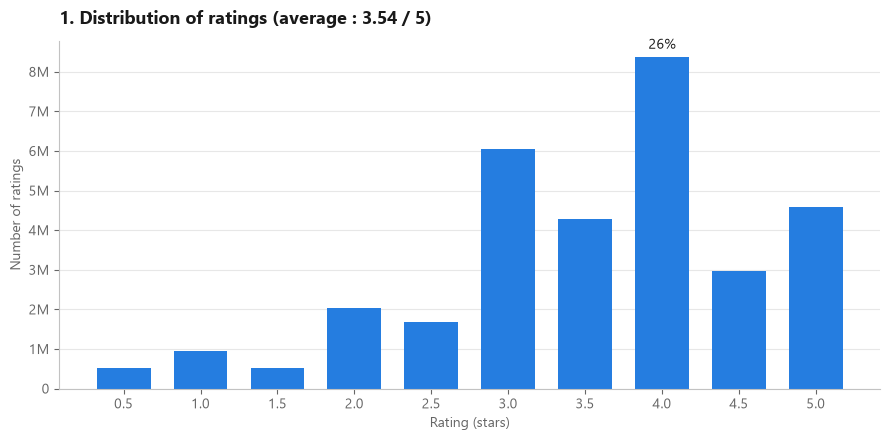

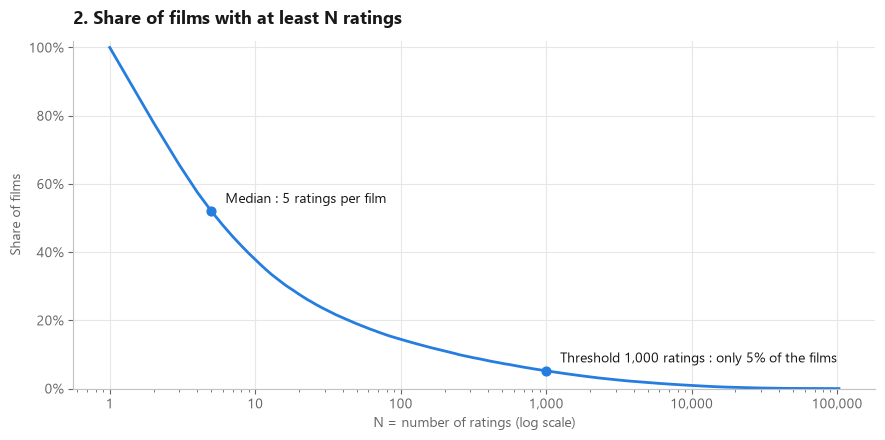

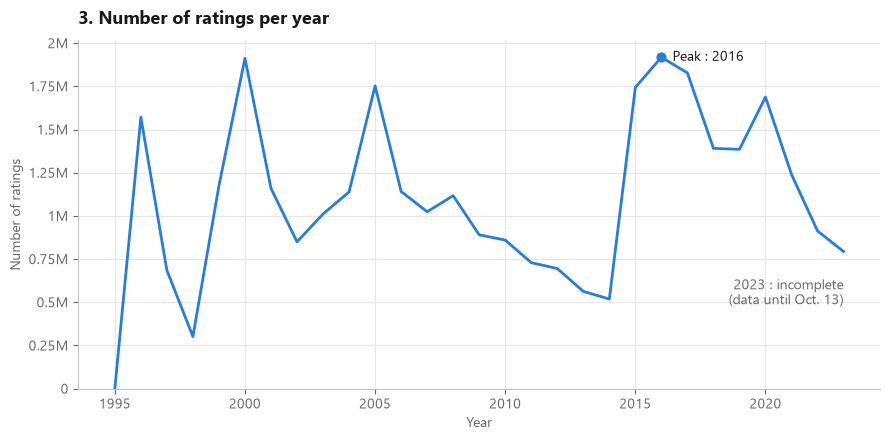

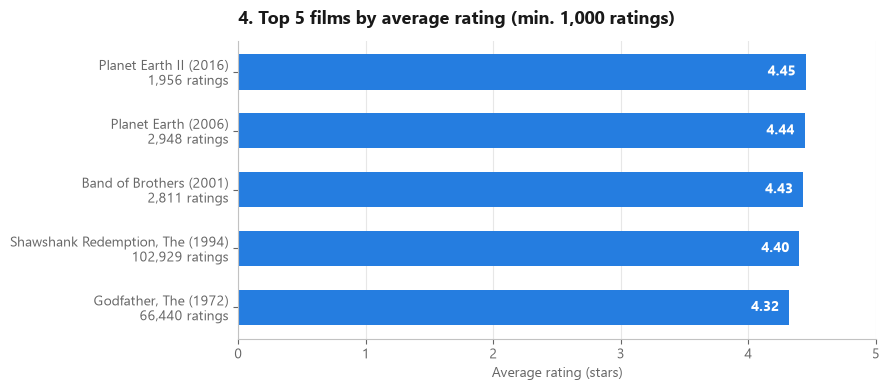

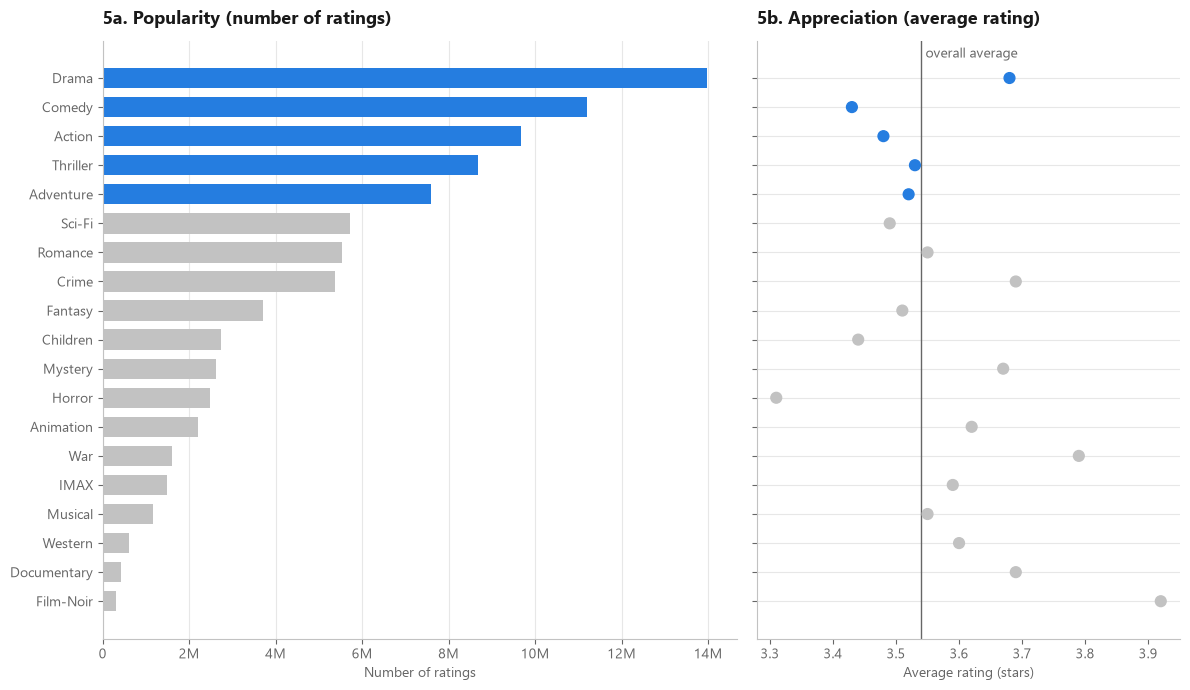

In [7]:
# - - - - - - - - - VISUALIZATIONS WITH PYTHON - - - - - - - - - #
# Spark does the heavy aggregations, then ONLY the small results go to pandas for plotting
# (never .toPandas() on the 32M ratings : it would load everything in the driver memory)

VISUALS_DIR = "visuals"  # PNG files, reusable in the slides and the README
os.makedirs(VISUALS_DIR, exist_ok=True)

# Chart style : one color for the data, gray for the context, light grid
BLUE, GRAY = "#257de0", "#c2c2c2"
INK, INK_2, GRID = "#191919", "#666666", "#e7e7e7"
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "axes.edgecolor": GRAY,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
})
millions = mticker.FuncFormatter(lambda x, _: "0" if x == 0 else f"{x / 1e6:g}M")


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(VISUALS_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()


# - - - Spark aggregations -> small pandas DataFrames - - - #
pdf_year_rating = (  # ~300 lines : number of ratings per (year, rating value)
    df_clean_ratings
    .withColumn("year", F.year(F.from_unixtime("timestamp")))
    .groupBy("year", "rating")
    .agg(
        F.count("*").alias("nb_ratings"),
        F.max("timestamp").alias("last_timestamp"),  # To detect an incomplete last year
    )
    .toPandas()
)
pdf_rating_dist = pdf_year_rating.groupby("rating")["nb_ratings"].sum()
pdf_per_year = pdf_year_rating.groupby("year")["nb_ratings"].sum().sort_index()
last_date = pd.to_datetime(pdf_year_rating["last_timestamp"].max(), unit="s")
pdf_ratings_per_film = df_movie_sums.select("nb_ratings").toPandas()["nb_ratings"]
pdf_top5 = df_top5_movies.toPandas()
pdf_genres = df_genre_stats.toPandas()

global_avg = np.average(pdf_rating_dist.index, weights=pdf_rating_dist.values)


# - - - 1. Distribution of ratings - - - #
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(pdf_rating_dist.index.astype(str), pdf_rating_dist.values, color=BLUE, width=0.7)
mode = pdf_rating_dist.idxmax()
ax.bar_label(
    bars,
    labels=[f"{v / total_ratings:.0%}" if r == mode else "" for r, v in pdf_rating_dist.items()],
    padding=4, color=INK,
)
ax.yaxis.set_major_formatter(millions)
ax.grid(axis="x", visible=False)
ax.set(title=f"1. Distribution of ratings (average : {global_avg:.2f} / 5)",
       xlabel="Rating (stars)", ylabel="Number of ratings")
save_fig(fig, "1_ratings_distribution")


# - - - 2. Share of films with at least N ratings (long tail) - - - #
sorted_counts = np.sort(pdf_ratings_per_film.values)
n_grid = np.unique(np.logspace(0, np.log10(sorted_counts[-1]), 300).astype(int))
share_at_least = 1 - np.searchsorted(sorted_counts, n_grid, side="left") / len(sorted_counts)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(n_grid, share_at_least, color=BLUE, linewidth=2)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_ylim(0, 1.02)

median_ratings = pdf_ratings_per_film.median()
share_reliable = (pdf_ratings_per_film >= MIN_RATINGS).mean()
for x, y, label in [
    (median_ratings, (pdf_ratings_per_film >= median_ratings).mean(),
     f"Median : {median_ratings:.0f} ratings per film"),
    (MIN_RATINGS, share_reliable,
     f"Threshold {MIN_RATINGS:,} ratings : only {share_reliable:.0%} of the films"),
]:
    ax.scatter([x], [y], color=BLUE, s=40, zorder=3)
    ax.annotate(label, (x, y), xytext=(10, 6), textcoords="offset points", color=INK)
ax.set(title="2. Share of films with at least N ratings",
       xlabel="N = number of ratings (log scale)", ylabel="Share of films")
save_fig(fig, "2_ratings_per_film")


# - - - 3. Number of ratings per year - - - #
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(pdf_per_year.index, pdf_per_year.values, color=BLUE, linewidth=2)
peak_year = pdf_per_year.idxmax()
ax.scatter([peak_year], [pdf_per_year.max()], color=BLUE, s=40, zorder=3)
ax.annotate(f"Peak : {peak_year}", (peak_year, pdf_per_year.max()),
            xytext=(8, 0), textcoords="offset points", va="center", color=INK)
last_year = pdf_per_year.index.max()
ax.annotate(f"{last_year} : incomplete\n(data until {last_date:%b. %d})",
            (last_year, pdf_per_year[last_year]),
            xytext=(0, -38), textcoords="offset points", ha="right", color=INK_2)
ax.yaxis.set_major_formatter(millions)
ax.set_ylim(bottom=0)
ax.set(title="3. Number of ratings per year", xlabel="Year", ylabel="Number of ratings")
save_fig(fig, "3_ratings_per_year")


# - - - 4. Top 5 films with the highest average ratings - - - #
pdf_top5_plot = pdf_top5.iloc[::-1]  # Best film at the top
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(
    [f"{t}\n{n:,} ratings" for t, n in zip(pdf_top5_plot["title"], pdf_top5_plot["nb_ratings"])],
    pdf_top5_plot["avg_rating"], color=BLUE, height=0.6,
)
for bar, rating in zip(bars, pdf_top5_plot["avg_rating"]):  # Value inside the end of each bar
    ax.text(bar.get_width() - 0.08, bar.get_y() + bar.get_height() / 2, f"{rating:.2f}",
            ha="right", va="center", color="white", fontweight="bold")
ax.set_xlim(0, 5)
ax.grid(axis="y", visible=False)
ax.set(title=f"4. Top 5 films by average rating (min. {MIN_RATINGS:,} ratings)",
       xlabel="Average rating (stars)")
save_fig(fig, "4_top5_movies")


# - - - 5. Genres : popularity vs. appreciation (top 5 most rated in blue) - - - #
pdf_genres_plot = pdf_genres.sort_values("nb_ratings")  # Most rated genre at the top
top5_genres = pdf_genres.head(5)["genre"].tolist()
colors = [BLUE if g in top5_genres else GRAY for g in pdf_genres_plot["genre"]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 7), sharey=True,
                               gridspec_kw={"width_ratios": [3, 2]})
ax1.barh(pdf_genres_plot["genre"], pdf_genres_plot["nb_ratings"], color=colors, height=0.7)
ax1.xaxis.set_major_formatter(millions)
ax1.grid(axis="y", visible=False)
ax1.set(title="5a. Popularity (number of ratings)", xlabel="Number of ratings")

ax2.scatter(pdf_genres_plot["avg_rating"], pdf_genres_plot["genre"], color=colors, s=60, zorder=3)
ax2.axvline(global_avg, color=INK_2, linewidth=1)
ax2.text(global_avg, len(pdf_genres_plot) - 0.4, " overall average", color=INK_2, va="bottom")
ax2.grid(axis="x", visible=False)
ax2.set(title="5b. Appreciation (average rating)", xlabel="Average rating (stars)")
save_fig(fig, "5_genres_popularity_vs_rating")

In [8]:
# - - - - - - - - - EXPORT FOR TABLEAU DESKTOP - - - - - - - - - #
# Spark prepares light aggregated tables : Tableau only has to draw them
# (instead of loading the 32M ratings, which would be very slow in Tableau)
TABLEAU_DIR = "data/tableau"
os.makedirs(TABLEAU_DIR, exist_ok=True)

# 1. One line per rated film : title, release year, genres, number of ratings, average rating
#    Genres "Action|Comedy" -> "Action, Comedy" : Tableau guesses the column separator by itself,
#    and the many "|" made it pick "|" instead of "," (all columns merged into one)
release_year = F.regexp_extract("title", r"\((\d{4})\)\s*$", 1)
df_tableau_movies = (
    df_clean_movies
    .join(df_movie_sums, on="movieId", how="inner")
    .withColumn("release_year", F.when(release_year != "", release_year.cast("int")))
    .withColumn("avg_rating", F.round(F.col("sum_ratings") / F.col("nb_ratings"), 2))
    .withColumn("genres", F.regexp_replace("genres", r"\|", ", "))
    .select("movieId", "title", "release_year", "genres", "nb_ratings", "avg_rating")
)
save_csv(df_tableau_movies, f"{TABLEAU_DIR}/tableau_movies.csv")

# 2. One line per (film, genre) : linked to tableau_movies on movieId, to filter films by genre
save_csv(df_movie_genres, f"{TABLEAU_DIR}/tableau_movie_genres.csv")

# 3. One line per genre : popularity and average rating
save_csv(df_genre_stats, f"{TABLEAU_DIR}/tableau_genres.csv")

# 4. One line per (year, rating value) : distribution of ratings and activity over time
(
    pdf_year_rating[["year", "rating", "nb_ratings"]]
    .sort_values(["year", "rating"])
    .to_csv(f"{TABLEAU_DIR}/tableau_ratings_by_year.csv", index=False)
)

print("Files for Tableau :", sorted(os.listdir(TABLEAU_DIR)))

Files for Tableau : ['tableau_genres.csv', 'tableau_movie_genres.csv', 'tableau_movies.csv', 'tableau_ratings_by_year.csv']


### **3. Modelisation Spark MLlibs : ABS**

Next step, in *modelisation.ipynb*